In [1]:
import pandas as pd
from xgboost import XGBRegressor
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

In [2]:
import datetime as dt

In [51]:
df=pd.read_csv("final_db.csv")
df.describe()

,Unnamed: 0,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue
count,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000
mean,181977.050653,20.101878,52.919115,97.511565,534.631428,506.183123,719.528914,673.243607,611.864179,119.222447
std,126711.336496,2.183414,4.409504,38.806471,34.001189,48.595386,29.902103,34.637434,41.189089,34.279827
min,0.000000,13.530000,38.160000,21.000000,408.000000,262.000000,514.000000,447.000000,355.000000,74.000000
25%,61525.000000,18.830000,49.580000,71.000000,508.000000,475.000000,704.000000,657.000000,591.000000,102.000000
50%,170410.500000,20.150000,53.340000,101.000000,522.000000,515.000000,720.000000,675.000000,614.000000,113.000000
75%,293281.250000,21.290000,56.550000,115.000000,557.000000,539.000000,738.000000,692.000000,637.000000,127.000000
max,416152.000000,26.140000,69.260000,591.000000,632.000000,626.000000,808.000000,777.000000,727.000000,918.000000


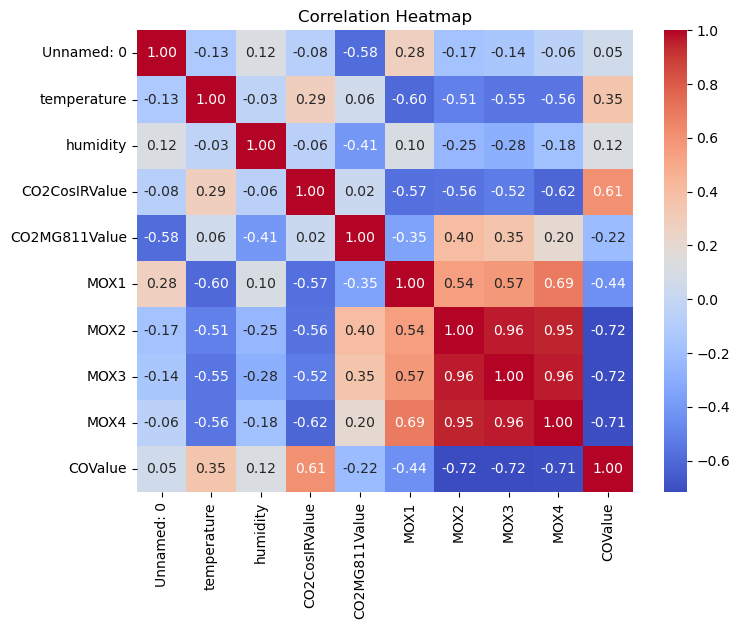

In [52]:
X = df.drop(['timestamp'], axis=1)
correlation_matrix = X.corr()
# Create a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [53]:
del df['Unnamed: 0']

In [54]:
predict_df = pd.DataFrame()
predict_df['timestamp'] = df.timestamp

In [55]:
def train_model(X, y, n_est = 100):
    my_model = XGBRegressor(n_estimators=n_est, learning_rate=0.5,max_depth=5,eval_metric='mae')
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=2,shuffle=True)
    my_model.fit(X_train, y_train)

    train_score = my_model.score(X_train,y_train)
    test_score = my_model.score(X_test,y_test)

    y_pred = my_model.predict(X_test)
    test_rmse = mean_squared_error(y_test, y_pred)

    my_model.fit(X,y)

    all_score = my_model.score(X,y)

    y_pred = my_model.predict(X)

    all_rmse = mean_squared_error(y, y_pred)
    
    return train_score, test_score, all_score, test_rmse, all_rmse, my_model


In [57]:
X = df.drop(['humidity','MOX3', 'MOX2','timestamp'], axis=1)
X = X.values
y = df['humidity'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_humidity = train_model(X, y, n_est=900)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9881474730686205 0.9847147819481747 0.9878039778579795 0.2966142096853029 0.23713567614678677


In [58]:
predict_df['humidity'] = model_humidity.predict(X)

In [59]:
df.columns

Index(['timestamp', 'temperature', 'humidity', 'CO2CosIRValue',
       'CO2MG811Value', 'MOX1', 'MOX2', 'MOX3', 'MOX4', 'COValue'],
      dtype='object')

In [63]:
X = df.drop(['temperature','MOX3', 'MOX2','timestamp'], axis=1)
X = X.values
y = df['temperature'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_temperature = train_model(X, y, n_est=1050)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9906410493211213 0.9879520378711497 0.9901157734779731 0.057395817062270205 0.04712095010683667


In [64]:
predict_df['temperature'] = model_temperature.predict(X)

In [66]:
X = df.drop(['CO2CosIRValue','MOX3', 'MOX2','timestamp'], axis=1)
X = X.values
y = df['CO2CosIRValue'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_CO2COS = train_model(X, y, n_est=850)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9951086905118876 0.9936460645063168 0.9949648459561193 9.604406949997804 7.582635355762519


In [67]:
predict_df['CO2CosIRValue'] = model_CO2COS.predict(X)

In [70]:
X = df.drop(['CO2MG811Value','MOX3', 'MOX2', 'timestamp'], axis=1)
X = X.values
y = df['CO2MG811Value'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_CO2MG8 = train_model(X, y, n_est=1500)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9917637580496366 0.9872043072344241 0.9913208694660463 14.770567442015375 10.033756171607779


In [71]:
predict_df['CO2MG811Value'] = model_CO2MG8.predict(X)

In [75]:
X = df.drop(['MOX1','MOX3', 'MOX2','timestamp'], axis=1)
X = X.values
y = df['MOX1'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_mox1 = train_model(X, y, n_est=1550)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9946702603496228 0.9916383394909207 0.9942889750633274 19.712841720872618 13.486623833386501


In [76]:
predict_df['MOX1'] = model_mox1.predict(X)

In [78]:
X = df.drop(['MOX2', 'MOX3', 'MOX4', 'timestamp'], axis=1)
X = X.values
y = df['MOX4'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_mox4 = train_model(X, y, n_est=1250)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9942304012493842 0.9917718261658306 0.9939459977253651 14.032283950889559 10.270842361125819


In [79]:
predict_df['MOX4'] = model_mox4.predict(X)

In [80]:
X = df.drop(['COValue','MOX3', 'MOX2','timestamp'], axis=1)
X = X.values
y = df['COValue'].values
train_score, test_score, all_score, test_rmse, all_rmse, model_COValue = train_model(X, y, n_est=1050)
print(train_score, test_score, all_score, test_rmse, all_rmse)

0.9947512126526337 0.9916633610371556 0.9945932866418591 9.985795754222684 6.353451228718892


In [81]:
predict_df['COValue'] = model_COValue.predict(X)

In [82]:
predict_df.to_csv("pred_value_full_data.csv")

In [83]:
# need to convert time string to time format for easy processing
df['recordtime'] = df['timestamp']
df.recordtime =df.recordtime.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
df.recordtime =df.recordtime.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [84]:
# sort values from small time to large time
# how much signal is difference from the prevous time to current time is important
df.sort_values(by='recordtime', inplace=True, ascending=True)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['timestamp'] = df['timestamp'].dt.floor(freq='1H')

In [85]:
# need to convert time string to time format for easy processing
predict_df['recordtime'] = predict_df['timestamp']
predict_df.recordtime =predict_df.recordtime.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
predict_df.recordtime =predict_df.recordtime.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [86]:
# sort values from small time to large time
# how much signal is difference from the prevous time to current time is important
predict_df.sort_values(by='recordtime', inplace=True, ascending=True)
predict_df['timestamp'] = pd.to_datetime(predict_df['timestamp'])
predict_df['timestamp'] = predict_df['timestamp'].dt.floor(freq='1H')

In [87]:
df['timestamp'].unique()

array(['2019-11-06T11:00:00.000000000', '2019-11-06T12:00:00.000000000',
       '2019-11-06T13:00:00.000000000', ...,
       '2021-02-13T09:00:00.000000000', '2021-02-13T10:00:00.000000000',
       '2021-02-13T11:00:00.000000000'], dtype='datetime64[ns]')

In [92]:
predict_df['timestamp'].head(50)

0    2019-11-06 11:00:00
1    2019-11-06 11:00:00
2    2019-11-06 11:00:00
3    2019-11-06 11:00:00
4    2019-11-06 11:00:00
5    2019-11-06 11:00:00
6    2019-11-06 11:00:00
7    2019-11-06 11:00:00
8    2019-11-06 11:00:00
9    2019-11-06 11:00:00
10   2019-11-06 11:00:00
11   2019-11-06 11:00:00
12   2019-11-06 11:00:00
13   2019-11-06 11:00:00
14   2019-11-06 11:00:00
15   2019-11-06 11:00:00
16   2019-11-06 11:00:00
17   2019-11-06 11:00:00
18   2019-11-06 11:00:00
19   2019-11-06 11:00:00
20   2019-11-06 11:00:00
21   2019-11-06 11:00:00
22   2019-11-06 11:00:00
23   2019-11-06 11:00:00
24   2019-11-06 11:00:00
25   2019-11-06 11:00:00
26   2019-11-06 11:00:00
27   2019-11-06 11:00:00
28   2019-11-06 11:00:00
29   2019-11-06 11:00:00
30   2019-11-06 11:00:00
31   2019-11-06 11:00:00
32   2019-11-06 11:00:00
33   2019-11-06 11:00:00
34   2019-11-06 11:00:00
35   2019-11-06 11:00:00
36   2019-11-06 11:00:00
37   2019-11-06 11:00:00
38   2019-11-06 11:00:00
39   2019-11-06 11:00:00


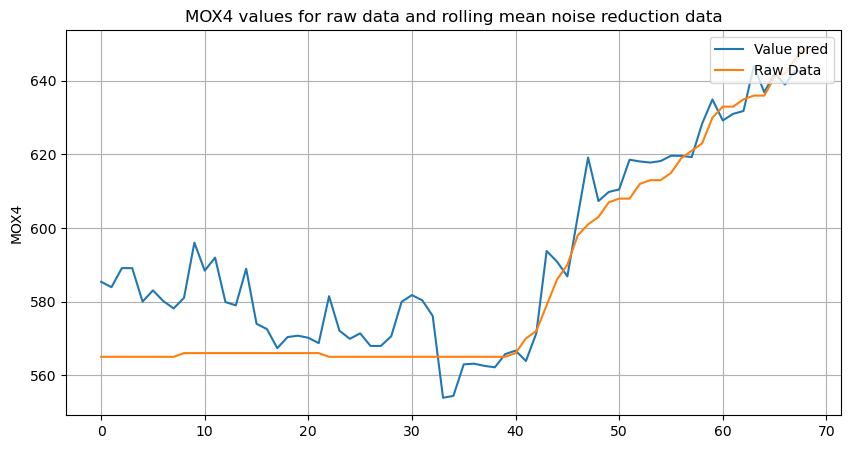

In [89]:
import matplotlib.pyplot as plt

# Assuming processed_df and df are your DataFrames

# Plotting the processed data
predict_df[predict_df['timestamp'] == '2019-11-06 11:00:00']['MOX4'].plot(kind='line', figsize=(10, 5), label='Value pred')
plt.title('MOX1 values for 1-hour timeframe after using rolling mean noise reduction technique ')
plt.ylabel('MOX1')
plt.legend(loc='upper right')
plt.grid(True)

# Plotting the raw data on the same plot
df[df['timestamp'] == '2019-11-06 11:00:00']['MOX4'].plot(kind='line', figsize=(10, 5), label='Raw Data')
plt.title('MOX4 values for raw data and rolling mean noise reduction data')
plt.ylabel('MOX4')
plt.legend(loc='upper right')
plt.grid(True)

# Display the combined plot
plt.show()

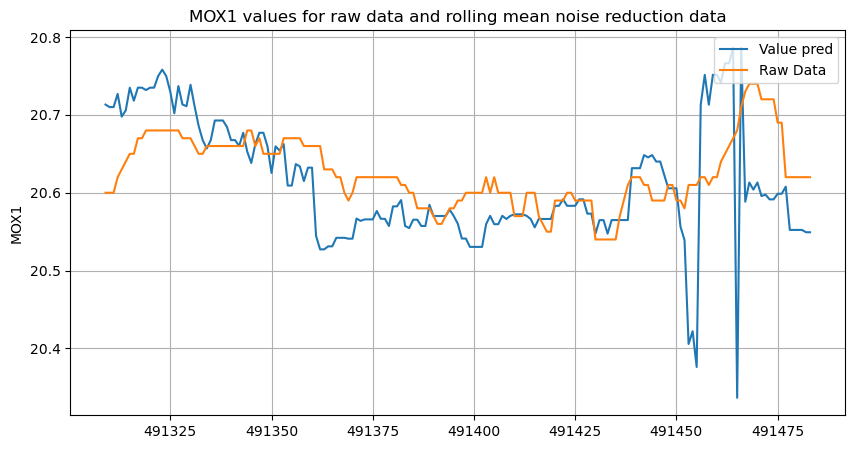

In [90]:
import matplotlib.pyplot as plt

# Assuming processed_df and df are your DataFrames

# Plotting the processed data
predict_df[predict_df['timestamp'] == '2021-02-13 11:00:00']['temperature'].plot(kind='line', figsize=(10, 5), label='Value pred')
plt.title('MOX1 values for 1-hour timeframe after using rolling mean noise reduction technique ')
plt.ylabel('MOX1')
plt.legend(loc='upper right')
plt.grid(True)

# Plotting the raw data on the same plot
df[df['timestamp'] == '2021-02-13 11:00:00']['temperature'].plot(kind='line', figsize=(10, 5), label='Raw Data')
plt.title('MOX1 values for raw data and rolling mean noise reduction data')
plt.ylabel('MOX1')
plt.legend(loc='upper right')
plt.grid(True)

# Display the combined plot
plt.show()

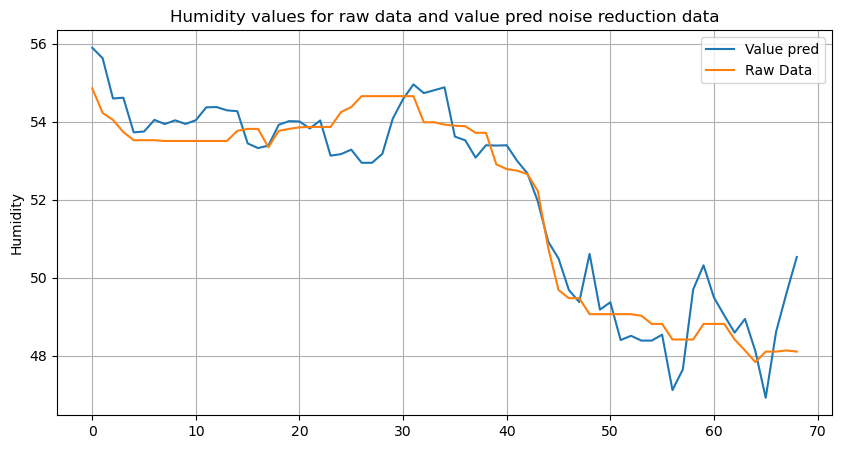

In [93]:
import matplotlib.pyplot as plt

# Assuming processed_df and df are your DataFrames

# Plotting the processed data
predict_df[predict_df['timestamp'] == '2019-11-06 11:00:00']['humidity'].plot(kind='line', figsize=(10, 5), label='Value pred')
plt.title('MOX1 values for 1-hour timeframe after using rolling mean noise reduction technique ')
plt.ylabel('MOX1')
plt.legend(loc='upper right')
plt.grid(True)

# Plotting the raw data on the same plot
df[df['timestamp'] == '2019-11-06 11:00:00']['humidity'].plot(kind='line', figsize=(10, 5), label='Raw Data')
plt.title('Humidity values for raw data and value pred noise reduction data')
plt.ylabel('Humidity')
plt.legend(loc='upper right')
plt.grid(True)

# Display the combined plot
plt.show()

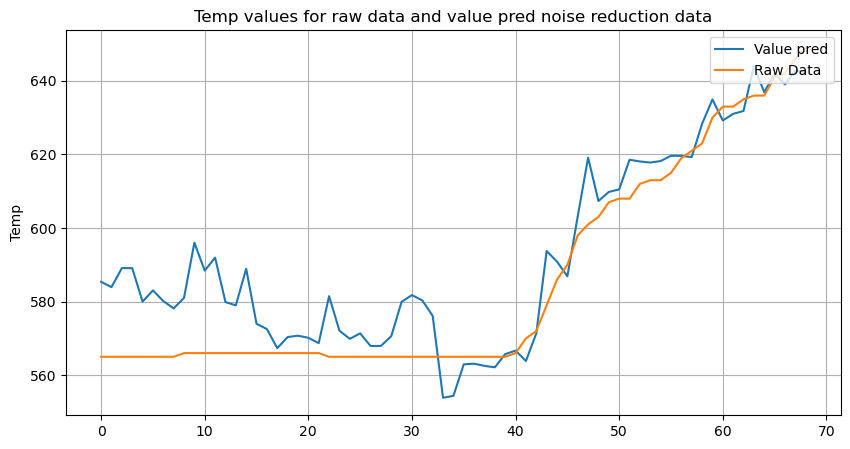

In [95]:
import matplotlib.pyplot as plt

# Assuming processed_df and df are your DataFrames

# Plotting the processed data
predict_df[predict_df['timestamp'] == '2019-11-06 11:00:00']['MOX4'].plot(kind='line', figsize=(10, 5), label='Value pred')
plt.title('MOX1 values for 1-hour timeframe after using rolling mean noise reduction technique ')
plt.ylabel('MOX1')
plt.legend(loc='upper right')
plt.grid(True)

# Plotting the raw data on the same plot
df[df['timestamp'] == '2019-11-06 11:00:00']['MOX4'].plot(kind='line', figsize=(10, 5), label='Raw Data')
plt.title('Temp values for raw data and value pred noise reduction data')
plt.ylabel('Temp')
plt.legend(loc='upper right')
plt.grid(True)

# Display the combined plot
plt.show()

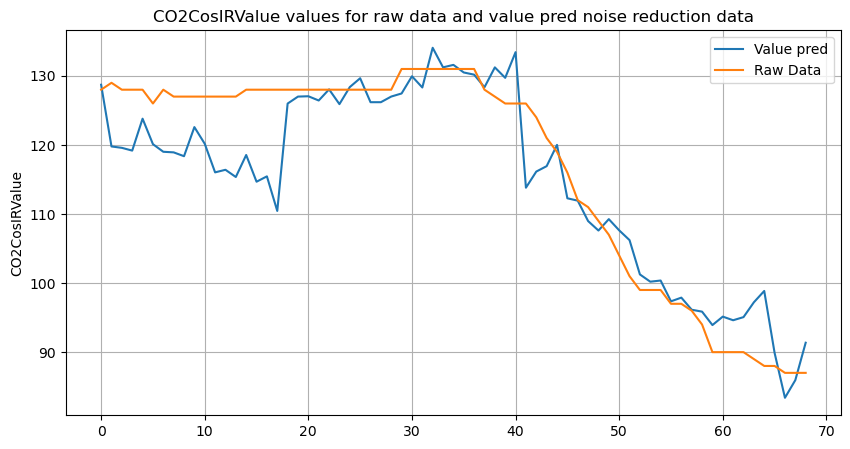

In [96]:
import matplotlib.pyplot as plt

# Assuming processed_df and df are your DataFrames

# Plotting the processed data
predict_df[predict_df['timestamp'] == '2019-11-06 11:00:00']['CO2CosIRValue'].plot(kind='line', figsize=(10, 5), label='Value pred')
plt.title('MOX1 values for 1-hour timeframe after using rolling mean noise reduction technique ')
plt.ylabel('MOX1')
plt.legend(loc='upper right')
plt.grid(True)

# Plotting the raw data on the same plot
df[df['timestamp'] == '2019-11-06 11:00:00']['CO2CosIRValue'].plot(kind='line', figsize=(10, 5), label='Raw Data')
plt.title('CO2CosIRValue values for raw data and value pred noise reduction data')
plt.ylabel('CO2CosIRValue')
plt.legend(loc='upper right')
plt.grid(True)

# Display the combined plot
plt.show()

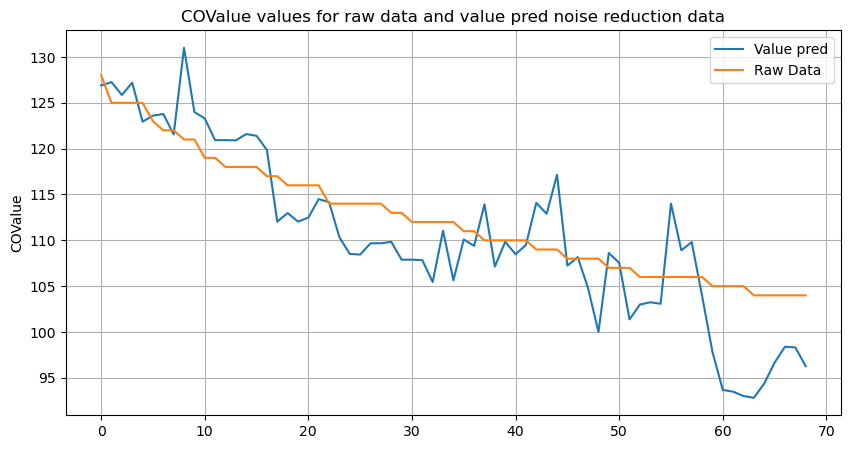

In [97]:
import matplotlib.pyplot as plt

# Assuming processed_df and df are your DataFrames

# Plotting the processed data
predict_df[predict_df['timestamp'] == '2019-11-06 11:00:00']['COValue'].plot(kind='line', figsize=(10, 5), label='Value pred')
plt.title('MOX1 values for 1-hour timeframe after using rolling mean noise reduction technique ')
plt.ylabel('MOX1')
plt.legend(loc='upper right')
plt.grid(True)

# Plotting the raw data on the same plot
df[df['timestamp'] == '2019-11-06 11:00:00']['COValue'].plot(kind='line', figsize=(10, 5), label='Raw Data')
plt.title('COValue values for raw data and value pred noise reduction data')
plt.ylabel('COValue')
plt.legend(loc='upper right')
plt.grid(True)

# Display the combined plot
plt.show()

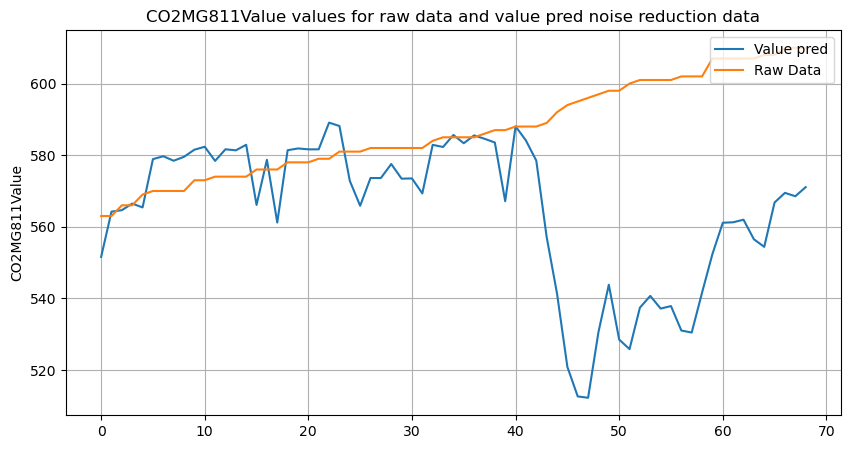

In [98]:
import matplotlib.pyplot as plt

# Assuming processed_df and df are your DataFrames

# Plotting the processed data
predict_df[predict_df['timestamp'] == '2019-11-06 11:00:00']['CO2MG811Value'].plot(kind='line', figsize=(10, 5), label='Value pred')
plt.title('MOX1 values for 1-hour timeframe after using rolling mean noise reduction technique ')
plt.ylabel('MOX1')
plt.legend(loc='upper right')
plt.grid(True)

# Plotting the raw data on the same plot
df[df['timestamp'] == '2019-11-06 11:00:00']['CO2MG811Value'].plot(kind='line', figsize=(10, 5), label='Raw Data')
plt.title('CO2MG811Value values for raw data and value pred noise reduction data')
plt.ylabel('CO2MG811Value')
plt.legend(loc='upper right')
plt.grid(True)

# Display the combined plot
plt.show()

In [99]:
df['timestamp'].unique()

array(['2019-11-06T11:00:00.000000000', '2019-11-06T12:00:00.000000000',
       '2019-11-06T13:00:00.000000000', ...,
       '2021-02-13T09:00:00.000000000', '2021-02-13T10:00:00.000000000',
       '2021-02-13T11:00:00.000000000'], dtype='datetime64[ns]')